In [ ]:
import numpy as np
import pandas as pd
import os
import PIL
import PIL.Image
from PIL import Image
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import shutil
from tensorflow.keras import datasets, layers, models
from sklearn.metrics import confusion_matrix
import seaborn as sns
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import ConfusionMatrixDisplay

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

path_to_dataset = "/content/drive/MyDrive/Colab Notebooks/Hand_Gestures.zip"

#place zip files inside dataset folder
import zipfile
zip_ref = zipfile.ZipFile(path_to_dataset, 'r')
zip_ref.extractall("/content/dataset")
zip_ref.close()

Mounted at /content/drive


In [ ]:
#set datapath and then create a list for the image folders
train_dir = "/content/dataset/Hand_Gestures/train/train"
val_dir = "/content/dataset/Hand_Gestures/val/val"
train_dir_list = os.listdir(train_dir)
val_dir_list = os.listdir(val_dir)

In [ ]:
train_df = pd.read_csv('/content/dataset/Hand_Gestures/train.csv')
val_df = pd.read_csv('/content/dataset/Hand_Gestures/val.csv')
train_df

,WIN_20180925_17_08_43_Pro_Left_Swipe_new;Left_Swipe_new;0
0,WIN_20180925_17_18_28_Pro_Left_Swipe_new;Left_...
1,WIN_20180925_17_18_56_Pro_Left_Swipe_new;Left_...
2,WIN_20180925_17_19_51_Pro_Left_Swipe_new;Left_...
3,WIN_20180925_17_20_14_Pro_Left_Swipe_new;Left_...
4,WIN_20180925_17_21_28_Pro_Left_Swipe_new;Left_...
...,...
657,WIN_20180907_16_38_23_Pro_Thumbs Up_new;Thumbs...
658,WIN_20180907_16_41_09_Pro_Thumbs Up_new;Thumbs...
659,WIN_20180907_16_42_05_Pro_Thumbs Up_new;Thumbs...
660,WIN_20180907_16_42_55_Pro_Thumbs Up_new;Thumbs...


The folders and labels are separated by ; in this case instead of the standard ,.

In [ ]:
#fixed
train_df = pd.read_csv('/content/dataset/Hand_Gestures/train.csv', sep = ';')
val_df = pd.read_csv('/content/dataset/Hand_Gestures/val.csv', sep =';')
train_df.columns = ["folder", "label", "classification"]
val_df.columns = ["folder", "label", "classification"]
print(len(train_df))
print(len(val_df))
print("Total folders with data samples for classifiers:" , len(train_df) + len(val_df))
train_df

662
99
Total folders with data samples for classifiers: 761


,folder,label,classification
0,WIN_20180925_17_18_28_Pro_Left_Swipe_new,Left_Swipe_new,0
1,WIN_20180925_17_18_56_Pro_Left_Swipe_new,Left_Swipe_new,0
2,WIN_20180925_17_19_51_Pro_Left_Swipe_new,Left_Swipe_new,0
3,WIN_20180925_17_20_14_Pro_Left_Swipe_new,Left_Swipe_new,0
4,WIN_20180925_17_21_28_Pro_Left_Swipe_new,Left_Swipe_new,0
...,...,...,...
657,WIN_20180907_16_38_23_Pro_Thumbs Up_new,Thumbs Up_new,4
658,WIN_20180907_16_41_09_Pro_Thumbs Up_new,Thumbs Up_new,4
659,WIN_20180907_16_42_05_Pro_Thumbs Up_new,Thumbs Up_new,4
660,WIN_20180907_16_42_55_Pro_Thumbs Up_new,Thumbs Up_new,4


In [ ]:
print("Training Data Labels:")
print(train_df["label"].unique())
print("Number of classes:", train_df["label"].nunique())
print("Validation Data Labels:")
print(val_df["label"].unique())
print("Number of classes:", val_df["label"].nunique())

Training Data Labels:
['Left_Swipe_new' 'Right_Swipe_new' 'Stop_new' 'Thumbs_Down_new'
 'Thumbs_Up_new' 'Left Swipe_new_Left Swipe_new' 'Right Swipe_new'
 'Stop Gesture_new' 'Thumbs Down_new' 'Thumbs Up_new']
Number of classes: 10
Validation Data Labels:
['Left_Swipe_new' 'Right_Swipe_new' 'Stop_new' 'Thumbs_Down_new'
 'Thumbs_Up_new' 'Left Swipe_new_Left Swipe_new' 'Right Swipe_new'
 'Stop Gesture_new' 'Thumbs Down_new' 'Thumbs Up_new']
Number of classes: 10


We wanted to obtain the class labels for further processing however there are 10 instead of 5 and looking at the labels there are some naming discreptacies that need to be fixed.
We are also confirming that the data labels match in both our training data and validation data.

In [ ]:
value_mapping = {
    'Left_Swipe_new': 'Left_Swipe', 'Left Swipe_new_Left Swipe_new':'Left_Swipe',
    'Right_Swipe_new': 'Right_Swipe', 'Right Swipe_new': 'Right_Swipe',
    'Stop_new': 'Stop', 'Stop Gesture_new': 'Stop',
    'Thumbs_Down_new': 'Thumbs_Down', 'Thumbs Down_new': 'Thumbs_Down',
    'Thumbs_Up_new': 'Thumbs_Up', 'Thumbs Up_new': 'Thumbs_Up',
    }

In [ ]:
train_df["label"] = train_df["label"].replace(value_mapping)
val_df["label"] = val_df["label"].replace(value_mapping)
print(train_df["label"].unique())
print("Number of classes:", train_df["label"].nunique())
train_df
len(val_df)

['Left_Swipe' 'Right_Swipe' 'Stop' 'Thumbs_Down' 'Thumbs_Up']
Number of classes: 5


99

Mapping sets a standard value for our labels that way there are no discreptancies due to naming inconsistencies making data analysis more reliable. This mapping will also work for the validation dataset since they had the same labels with the same naming discreptancies

The folder structure for this is messy. There are multiple folders with pictures for the same class so now we need to rebuild the folder structure so processing images across all folders can be done efficiently and effectively.

In [ ]:
#dataset new paths
base = "/content/Hand_Gestures"
train_n = "/content/Hand_Gestures/train"
val_n = "/content/Hand_Gestures/val"
#create new folders
os.makedirs(train_n, exist_ok=True)
os.makedirs(val_n, exist_ok=True)
#creating folders for each class label
for label in train_df["label"].unique():
  os.makedirs(os.path.join(train_n, label), exist_ok=True)
  os.makedirs(os.path.join(val_n, label), exist_ok=True)
#copying images into respective folders
#training
for index, row in train_df.iterrows():
  sample = row["folder"]
  label = row["label"]
  source = os.path.join(train_dir, sample)
  dst = os.path.join(train_n, label)
  for img in os.listdir(source):
    source_img = os.path.join(source, img)
    dst_img = os.path.join(dst, f"{sample}_{img}")
    #copies image into destination
    shutil.copy(source_img, dst_img)


In [ ]:
#validation
for index, row in val_df.iterrows():
  sample = row["folder"]
  label = row["label"]
  source = os.path.join(val_dir, sample)
  dst = os.path.join(val_n, label)
  for img in os.listdir(source):
    source_img = os.path.join(source, img)
    dst_img = os.path.join(dst, f"{sample}_{img}")
    #copies image into destination
    shutil.copy(source_img, dst_img)

In [ ]:
from tensorflow.python.ops.gen_nn_ops import avg_pool
from IPython.core.interactiveshell import available_events
for label in os.listdir(train_n):
  folder = os.path.join(train_n, label)
  size = []
  sample_count = 0
  for filename in os.listdir(folder):
    img_path = os.path.join(folder, filename)
    img = Image.open(img_path)
    size.append(img.size)
    sample_count += 1
  print(label)
  size = np.array(size)
  min_size = np.min(size, axis=0)
  max_size = np.max(size, axis=0)
  avg_size = np.mean(size, axis=0)
  print(min_size)
  print(max_size)
  print(avg_size)
  print(sample_count)

Left_Swipe
[160 120]
[360 360]
[219.25925926 191.11111111]
4050
Stop
[160 120]
[360 360]
[216.92307692 188.30769231]
3900
Thumbs_Up
[160 120]
[360 360]
[218.53658537 190.24390244]
3690
Thumbs_Down
[160 120]
[360 360]
[214.01459854 184.81751825]
4110
Right_Swipe
[160 120]
[360 360]
[209.6350365 179.5620438]
4110


We have the ranges of image sizes per class label since this is what I will be using for the image rezise. I also obtained the amount of samples each label has. Based on the information we have more Thumbs_Down and Right_Swipe samples than for the other classes, meaning that it will be more likely that our CNN and LSTM will be better at classifying images that correspond to these labels

In [ ]:
#tf.keras.preprocessing resizes the images for us and assigns labels based on the folders name
train_n_ds = tf.keras.preprocessing.image_dataset_from_directory('/content/Hand_Gestures/train', label_mode= 'int', seed = 42, image_size = (32,32))
val_n_ds = tf.keras.preprocessing.image_dataset_from_directory('/content/Hand_Gestures/val', label_mode= 'int', seed = 42, image_size = (32,32))

Found 19860 files belonging to 5 classes.
Found 2970 files belonging to 5 classes.


tf.keras.preprocessing places all of our images in a teras dataset.
It resizes all the images to (32,32) since this is the smallest standard size for CNN images. Ideally it would be bigger since we can lose multiple feautures due to distortion but the run time takes very long.
It also assigns the class labels based on the folder's names. We decided to make the labels int since this correlates with the original classification values given in the train and val csv. The batch size was left as default of 32 and the seed was set to 42 since we left shuffling on

Images shape: (32, 32, 32, 3)
Labels: tf.Tensor([1 1 0 0 3 4 0 2 1 0 4 3 4 4 4 1 2 0 3 4 4 2 4 1 1 2 1 4 1 4 2 4], shape=(32,), dtype=int32)
Images: 32
Label 1


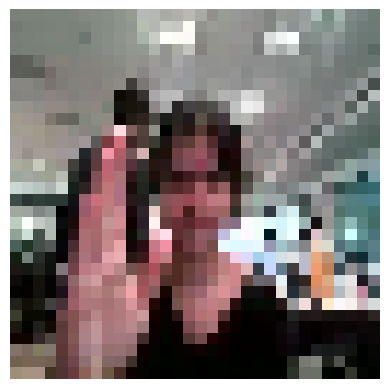

Label 1


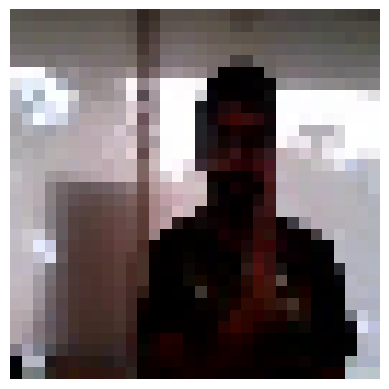

Label 0


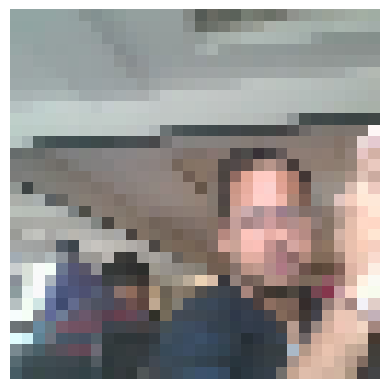

Label 0


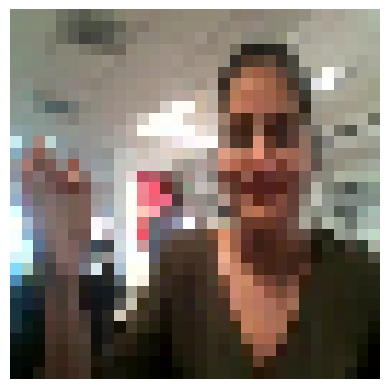

Label 3


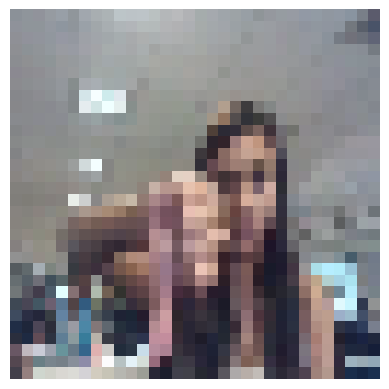

Label 4


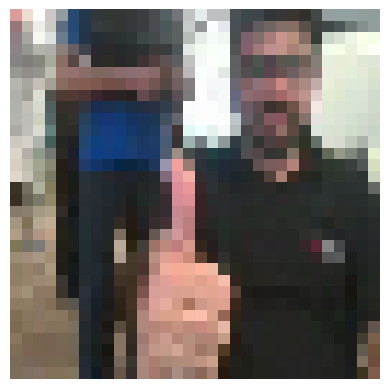

Label 0


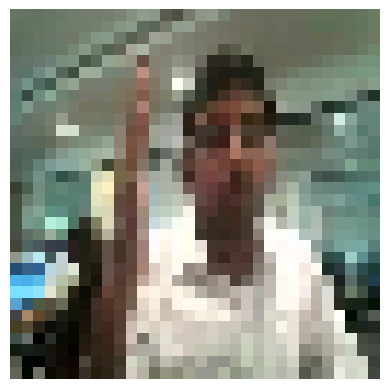

Label 2


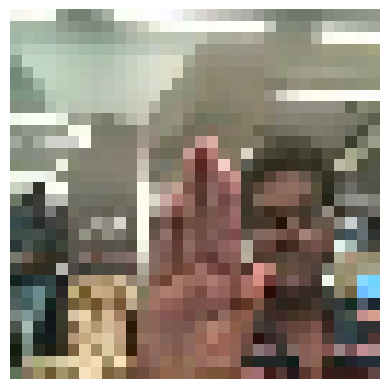

Label 1


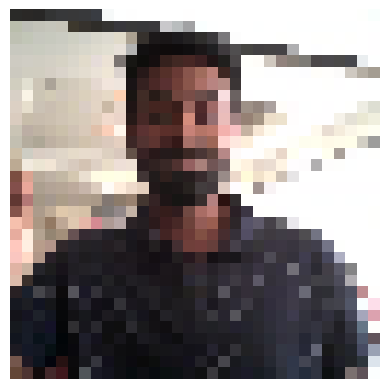

Label 0


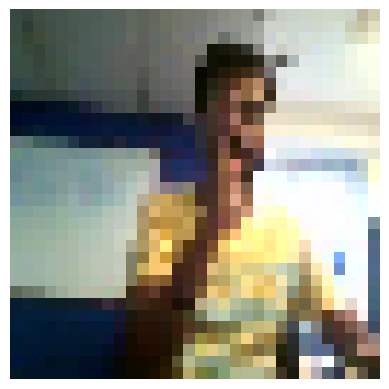

Label 4


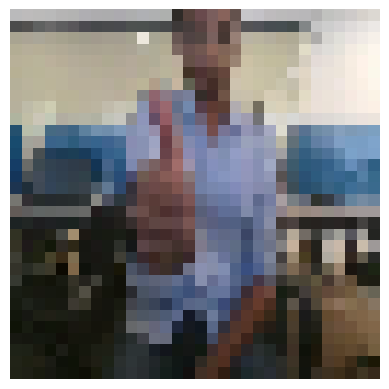

Label 3


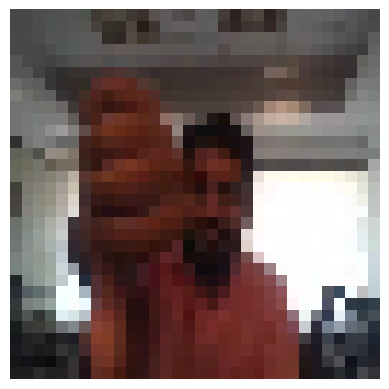

Label 4


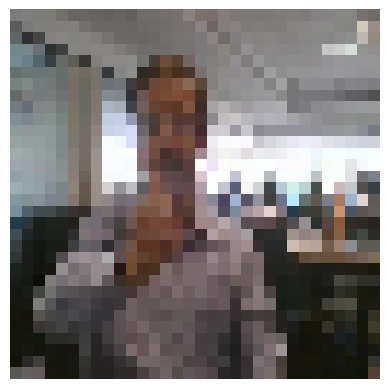

Label 4


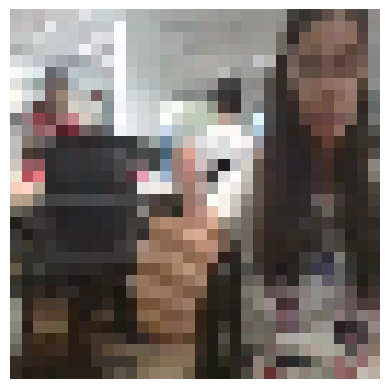

Label 4


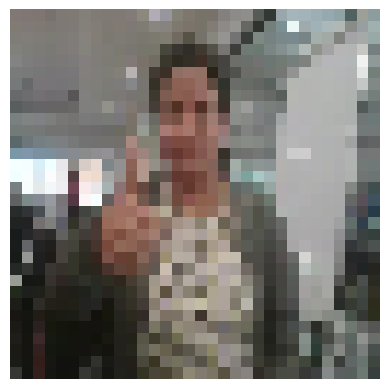

Label 1


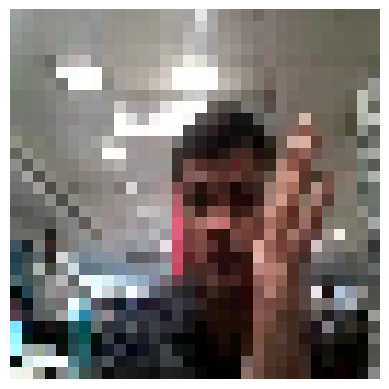

Label 2


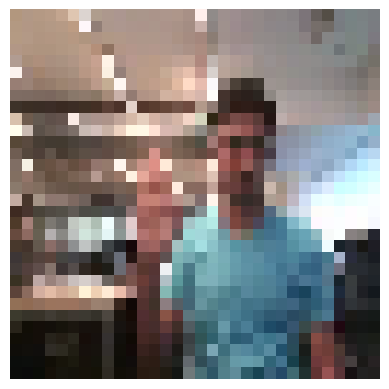

Label 0


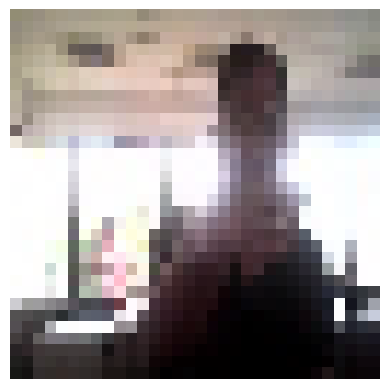

Label 3


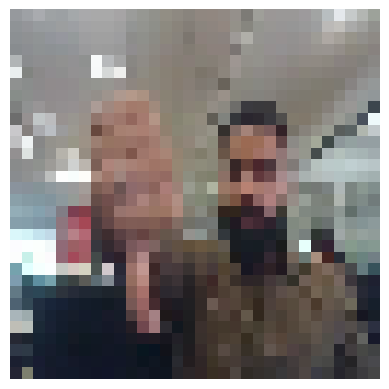

Label 4


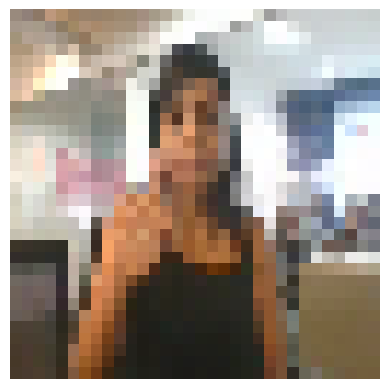

Label 4


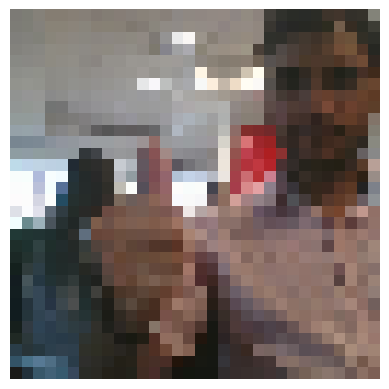

Label 2


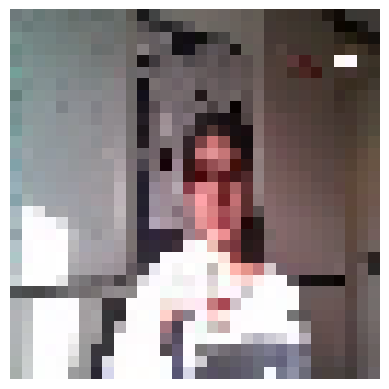

Label 4


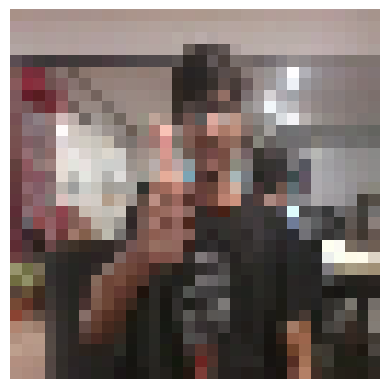

Label 1


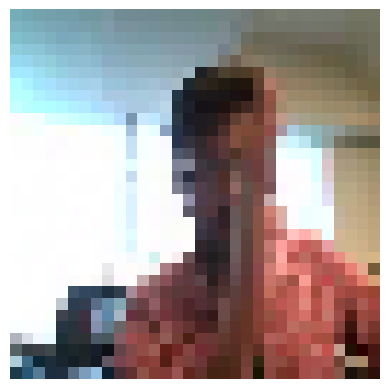

Label 1


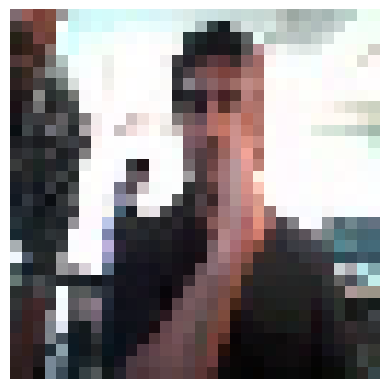

Label 2


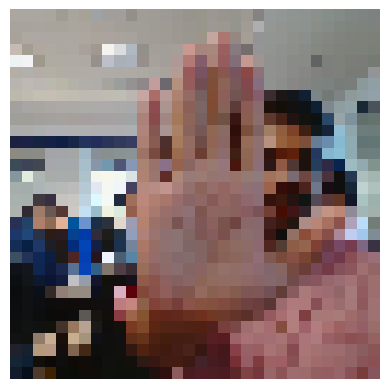

Label 1


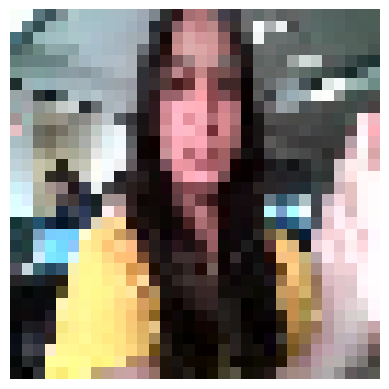

Label 4


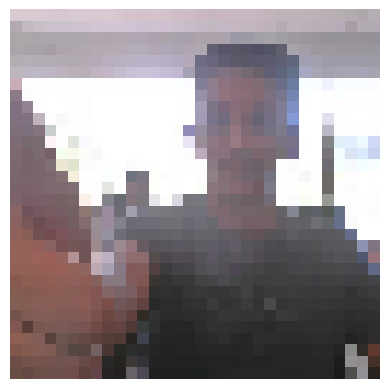

Label 1


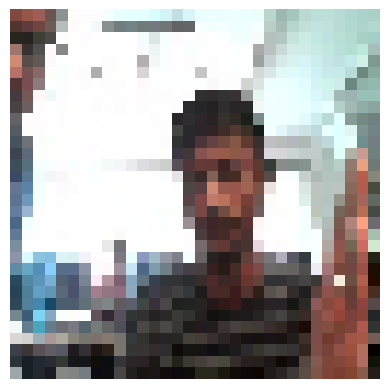

Label 4


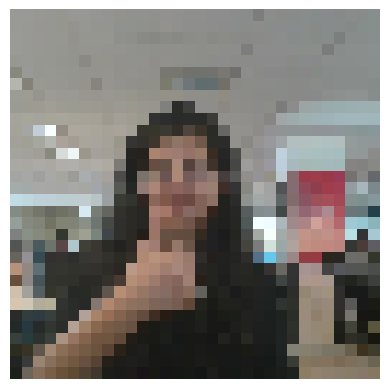

Label 2


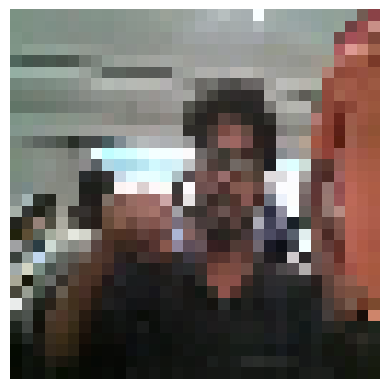

Label 4


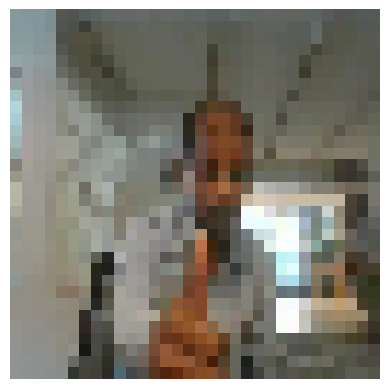

In [ ]:
for images, labels in train_n_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels:", labels)
    print("Images:", images.shape[0])

    for i in range(len(images)):
      label = np.array(labels[i])
      plt.imshow(images[i].numpy().astype("uint8"))
      print("Label", label)
      plt.axis('off')
      plt.show()

We wanted to check that images and their labels coordinated with the ones given by the training_df. To do this I went through one batch and was able to verify this!
We also used it as an exploration of how to view these datasets

#CNN

In [ ]:
cnn = models.Sequential()
#convolutional layer set up. relu extracts edges and color features
cnn.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
#picks maximum value in 2x2 pixels for the feature map
cnn.add(layers.MaxPooling2D((2, 2)))
#adds more layers which can learn 64 filters
cnn.add(layers.Conv2D(64, (3, 3), activation='relu'))
#input layer to reduce dimensions again
cnn.add(layers.MaxPooling2D((2, 2)))
#Third convolutionary layer with 64 filters
cnn.add(layers.Conv2D(64, (3, 3), activation='relu'))

cnn.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,320 (220.00 KB)

 Trainable params: 56,320 (220.00 KB)

 Non-trainable params: 0 (0.00 B)

This is setting our CNN. We are following the example given in tensor flow for CNN, and adjusting accordingly.

First convolutionary layer:
* 2D convolutionary layer, because we are using images
* 32 kernels in the layer --> 32 separate 3x3 pixel patches per kernel creating the filter maps
* The kernels learn the feautures
* relu: standard cnn activation function. After the kernels are used it replaces negative values with 0.
* Lets the model know the dimensions of our images 32x32 with a depth of 3.

MaxPooling:
* downsizes the size of our images by cutting it in half
* Every 2x2 block's max value is selected

The same idea continues for the next pooling

2nd and 3rd convolutionary layer:
* we now used this down sized feature map and set up 64 kernels with 3x3 piexel patches and use the rule activation for pooling


In [ ]:
cnn.add(layers.Flatten())
cnn.add(layers.Dense(100, activation='relu'))
cnn.add(layers.Dense(5))

cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       102,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           505 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 159,325 (622.36 KB)

 Trainable params: 159,325 (622.36 KB)

 Non-trainable params: 0 (0.00 B)

We now flatten our last convolutionary layer to 1D for dense layer processing.
100 neurons were chosen since this was recommended. This number can be found using cross-validation and is important since a small amount of neurons can lead to underfitting and a large amount of neurons lead to overfitting.However, since our data size is so large it would take too long to do this process.
Dense(5) produces output scores for each class which helps the model classify each image accordingly

In [ ]:
cnn.compile(optimizer = 'adam', loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics = ['accuracy'])

history = cnn.fit(train_n_ds, epochs=10, validation_data = val_n_ds)

Epoch 1/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 73s 115ms/step - accuracy: 0.5401 - loss: 2.8045 - val_accuracy: 0.6034 - val_loss: 1.8121
Epoch 2/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 83s 134ms/step - accuracy: 0.9608 - loss: 0.1223 - val_accuracy: 0.5633 - val_loss: 2.7623
Epoch 3/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 72s 115ms/step - accuracy: 0.9792 - loss: 0.0672 - val_accuracy: 0.5242 - val_loss: 3.0165
Epoch 4/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 74s 102ms/step - accuracy: 0.9792 - loss: 0.0722 - val_accuracy: 0.5768 - val_loss: 2.8916
Epoch 5/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 65s 104ms/step - accuracy: 0.9822 - loss: 0.0579 - val_accuracy: 0.5842 - val_loss: 2.9275
Epoch 6/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 64s 103ms/step - accuracy: 0.9826 - loss: 0.0526 - val_accuracy: 0.5367 - val_loss: 4.1646
Epoch 7/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 83s 105ms/step - accuracy: 0.9885 - loss: 0.0389 - val_accuracy: 0.5485 - val_loss: 3.5231
Epoch 8/10
621/621 ━━━━━━━━━━━━━━━━━━━━ 87s 112ms/step - accuracy: 0.9879 - loss: 0

* adam: optimizer commonly used for CNN. It adjust the learning rate for each weight based on past losses in order to reduce it
* SparseCategoricalCrossentropy was chosen since we have integers as our categorical labels.
* Accuracy was used as our metric for training since this is the only one allowed by this function for multiple classifications without having to import other methods. This however is not ideal since we have a skewed datset

93/93 - 6s - 60ms/step - accuracy: 0.5253 - loss: 5.1460


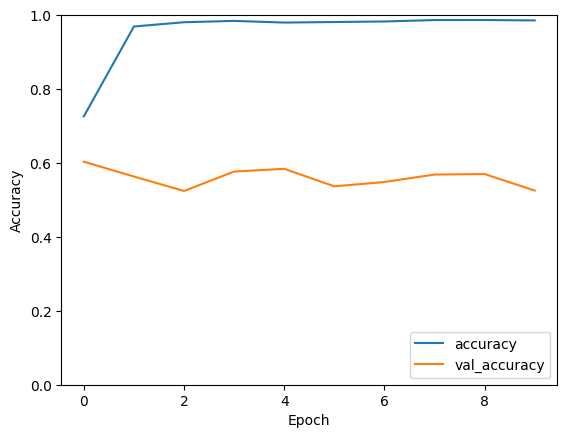

In [ ]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
test_loss, test_acc = cnn.evaluate(val_n_ds, verbose=2)

In [ ]:
val_pred = cnn.predict(val_n_ds)
val_pred = np.argmax(val_pred, axis=1)

y_true = []
for images, labels in val_n_ds:
    y_true.extend(labels.numpy())

93/93 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step


We want to obtain the classification predictions given from our cnn since accuracy wont be enough to tell us how well our model did. Afterwards I will use this to create a confusion matrix and calculate the model's metrics

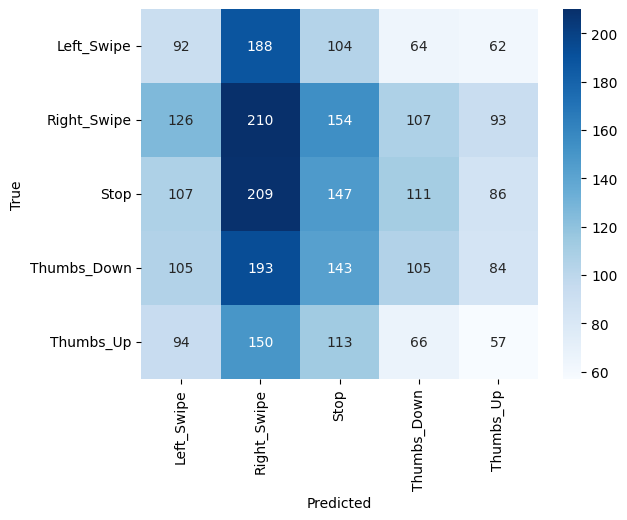

              precision    recall  f1-score   support

  Left_Swipe       0.18      0.18      0.18       510
 Right_Swipe       0.22      0.30      0.26       690
        Stop       0.22      0.22      0.22       660
 Thumbs_Down       0.23      0.17      0.19       630
   Thumbs_Up       0.15      0.12      0.13       480

    accuracy                           0.21      2970
   macro avg       0.20      0.20      0.20      2970
weighted avg       0.20      0.21      0.20      2970



In [ ]:
y_true = np.array(y_true)
cnn_cm = confusion_matrix(y_true, val_pred)
class_names = ['Left_Swipe', 'Right_Swipe', 'Stop', 'Thumbs_Down', 'Thumbs_Up']
sns.heatmap(cnn_cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

print(classification_report(y_true,val_pred, target_names=class_names))


#CNN with RNN-LSTM

RNN-LSTM is sequence base threfore we will re-process our data to make it sequential and/or be processed as such

In [ ]:
def sequences(folder):
  frames = os.listdir(folder)
  images = []

  for f in frames[:5]:
    img_path = os.path.join(folder, f)
    img = tf.keras.utils.load_img(img_path, target_size=(32,32))
    img = tf.keras.utils.img_to_array(img) / 255.0
    images.append(img)
  while len(images) < 5:
    images.append(np.zeros((32, 32, 3)))

  return np.array(images)

This functions goes through each folder and creates a sequence of images. It also makes sure all images are the same size. The same image size is used for this as before so results are comparable

In [ ]:
def dataset(data,base_dir):
  X = []
  y = []
  for _, row in data.iterrows():  # iterrows() correct spelling
    folder_name = row["folder"]
    label = row["label"]
    folder_path = os.path.join(base_dir, folder_name)

    if not os.path.exists(folder_path):
      continue

    X.append(sequences(folder_path))
    y.append(label)
  return np.array(X), np.array(y)

This function places the sequences into two datasets for our model to go through

In [ ]:
X_train, y_train = dataset(train_df, '/content/dataset/Hand_Gestures/train/train')
X_val, y_val = dataset(val_df, '/content/dataset/Hand_Gestures/val/val')

print(X_train.shape)
print(y_train.shape)

(662, 5, 32, 32, 3)
(662,)


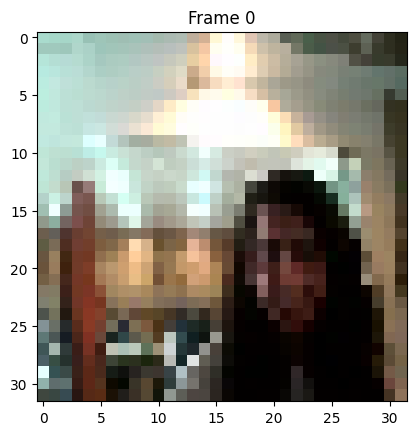

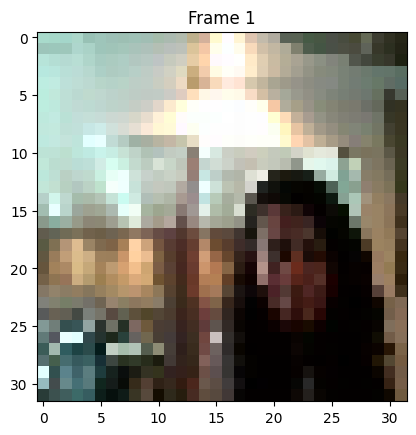

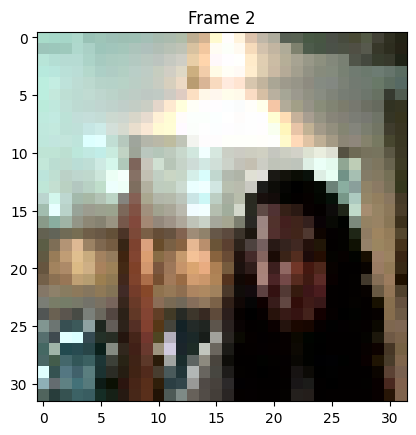

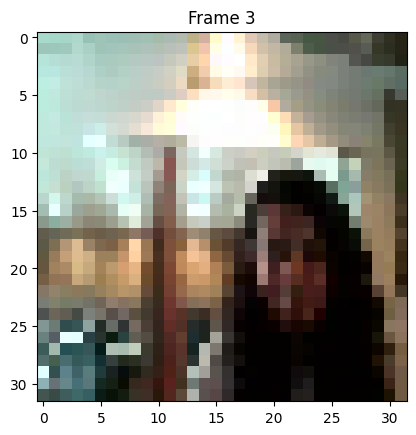

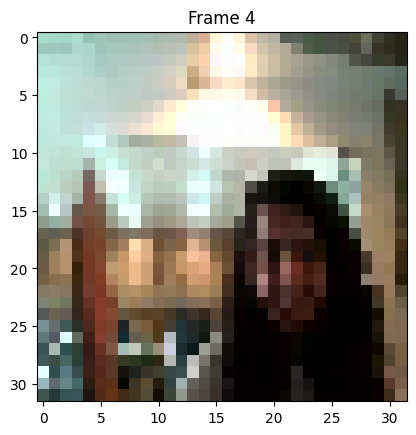

In [ ]:
for i in range(5):
    plt.imshow(X_train[0][i].astype('float32'))
    plt.title(f"Frame {i}")
    plt.show()

Organizes our training and validation values with image framing

In [ ]:
lbl = LabelEncoder()

# Fit on all training labels
lbl.fit(y_train)

# Transform string labels to integers
y_train_enc = lbl.transform(y_train)
y_val_enc = lbl.transform(y_val)

print(y_train_enc[:500])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 

We need to encode the string values into an integer classification to value for our model to work

In [ ]:
cnn_r = models.Sequential()
cnn_r.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
cnn_r.add(layers.MaxPooling2D((2, 2)))
cnn_r.add(layers.Conv2D(64, (3, 3), activation='relu'))
cnn_r.add(layers.MaxPooling2D((2, 2)))
cnn_r.add(layers.Conv2D(64, (3, 3), activation='relu'))
cnn_r.add(layers.Flatten())
cnn_r.add(layers.Dense(100, activation='relu'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


To use CNN alongside RNN we are using CNN not as a classifier but as a feature processor. This is because CNN's kernels are able to learn patterns and disregard things that are uncorrelated

In [ ]:
rnn_lstm = models.Sequential()
rnn_lstm.add(layers.TimeDistributed(cnn_r, input_shape=(5, 32,32,3,)))
rnn_lstm.add(layers.LSTM(64,return_sequences=False))
rnn_lstm.add(layers.Dense(5))
rnn_lstm.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/wrapper.py:27: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed_1              │ (None, 5, 100)         │       158,820 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 201,385 (786.66 KB)

 Trainable params: 201,385 (786.66 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
rnn_lstm.compile(optimizer = 'adam', loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics = ['accuracy'])
history = rnn_lstm.fit(X_train, y_train_enc, epochs=10, validation_data=(X_val, y_val_enc))

Epoch 1/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 222ms/step - accuracy: 0.1953 - loss: 1.6091 - val_accuracy: 0.2929 - val_loss: 1.5772
Epoch 2/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 6s 273ms/step - accuracy: 0.2833 - loss: 1.5565 - val_accuracy: 0.4343 - val_loss: 1.4109
Epoch 3/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 191ms/step - accuracy: 0.4537 - loss: 1.3586 - val_accuracy: 0.5253 - val_loss: 1.2233
Epoch 4/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 281ms/step - accuracy: 0.4535 - loss: 1.3311 - val_accuracy: 0.5758 - val_loss: 1.2062
Epoch 5/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 183ms/step - accuracy: 0.5242 - loss: 1.1868 - val_accuracy: 0.5051 - val_loss: 1.2403
Epoch 6/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 182ms/step - accuracy: 0.5580 - loss: 1.0973 - val_accuracy: 0.5556 - val_loss: 1.1670
Epoch 7/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 6s 274ms/step - accuracy: 0.6503 - loss: 0.9508 - val_accuracy: 0.5253 - val_loss: 1.1839
Epoch 8/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 188ms/step - accuracy: 0.6719 - loss: 0.8829 - val_accuracy: 0.

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


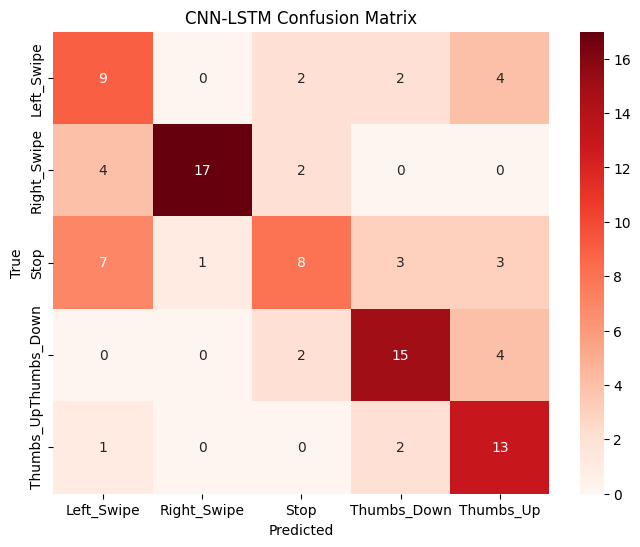

              precision    recall  f1-score   support

  Left_Swipe       0.43      0.53      0.47        17
 Right_Swipe       0.94      0.74      0.83        23
        Stop       0.57      0.36      0.44        22
 Thumbs_Down       0.68      0.71      0.70        21
   Thumbs_Up       0.54      0.81      0.65        16

    accuracy                           0.63        99
   macro avg       0.63      0.63      0.62        99
weighted avg       0.65      0.63      0.63        99



In [ ]:
y_pred = rnn_lstm.predict(X_val)
y_pred = np.argmax(y_pred, axis=1)


rnn_lstm_cm = confusion_matrix(y_val_enc, y_pred)

class_names = ['Left_Swipe', 'Right_Swipe', 'Stop', 'Thumbs_Down', 'Thumbs_Up']


plt.figure(figsize=(8,6))
sns.heatmap(rnn_lstm_cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('CNN-LSTM Confusion Matrix')
plt.show()
print(classification_report(y_val_enc, y_pred, target_names=class_names))

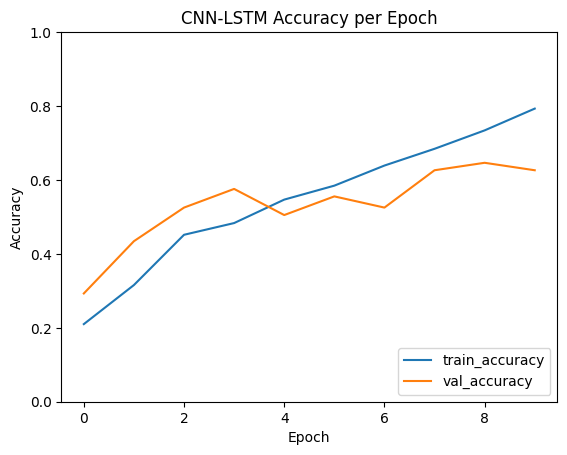

In [ ]:
plt.plot(history.history['accuracy'], label='train_accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
plt.title("CNN-LSTM Accuracy per Epoch")
plt.show()

#Comparitive Analysis

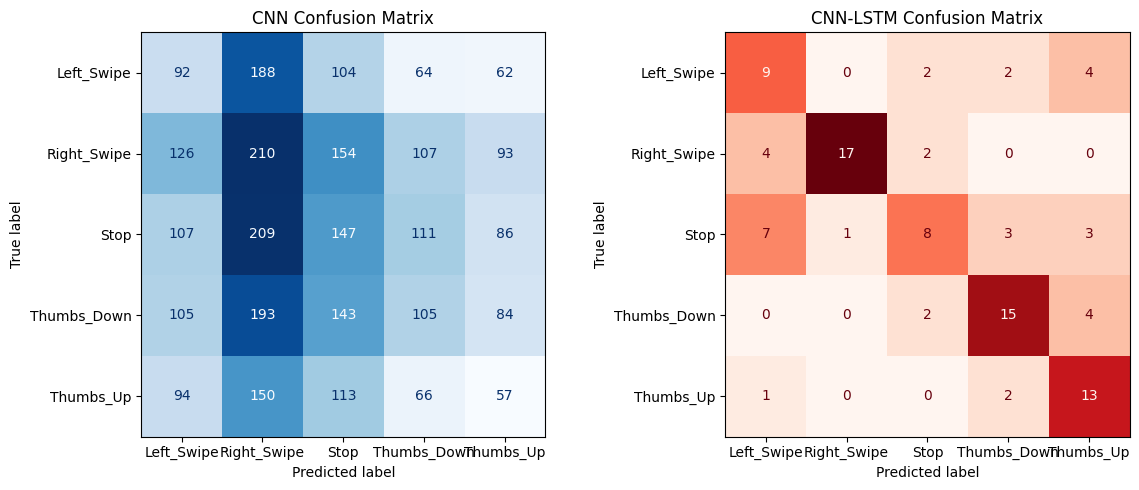

CNN:
              precision    recall  f1-score   support

  Left_Swipe       0.18      0.18      0.18       510
 Right_Swipe       0.22      0.30      0.26       690
        Stop       0.22      0.22      0.22       660
 Thumbs_Down       0.23      0.17      0.19       630
   Thumbs_Up       0.15      0.12      0.13       480

    accuracy                           0.21      2970
   macro avg       0.20      0.20      0.20      2970
weighted avg       0.20      0.21      0.20      2970

CNN-LSTM:
              precision    recall  f1-score   support

  Left_Swipe       0.43      0.53      0.47        17
 Right_Swipe       0.94      0.74      0.83        23
        Stop       0.57      0.36      0.44        22
 Thumbs_Down       0.68      0.71      0.70        21
   Thumbs_Up       0.54      0.81      0.65        16

    accuracy                           0.63        99
   macro avg       0.63      0.63      0.62        99
weighted avg       0.65      0.63      0.63        99



In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

ConfusionMatrixDisplay(cnn_cm, display_labels=class_names).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('CNN Confusion Matrix')

ConfusionMatrixDisplay(rnn_lstm_cm, display_labels=class_names).plot(ax=axes[1], cmap='Reds', colorbar=False)
axes[1].set_title('CNN-LSTM Confusion Matrix')

plt.tight_layout()
plt.show()
print("CNN:")
print(classification_report(y_true,val_pred, target_names=class_names))
print("CNN-LSTM:")
print(classification_report(y_val_enc, y_pred, target_names=class_names))

According to these values, it is clear that the CNN implementation with RNN_LSTM performs best. This makes sense, not only because we are using deeper feature extraction and processing through the CNN, but also because it works well with our datasets that include movement.
I will now focus on the F1-score, since it provides the best interpretation for this dataset, as it combines recall and precision—the main aspects we want our model to optimize.
The F1-score in both models confirms our expectation: we obtain better results for Right_Swipe, as this clas has the largest number of samples.
It also shows that we achieved around 80% for this class using RNN-LSTM, which is significantly higher than the results from CNN-only classification, with Right_Swipe having the highest improvement of 67%.
This suggests that, if we were provided with more samples for the other categories, using this model would likely gives us the best overall performance for completing our task.

#Ethics

For our specific problem, the database provided hand gestures that needed to be classified in order to control a TV. This is definitely an innovative approach to an everyday electronic device; however, it raises multiple questions and red flags. Primarily, for this to work, the TV would need to be recording the user, which raises privacy concerns, as this is a device that is kept inside homes. User data could be collected without their knowledge, which is unfortunately not uncommon nowadays. While this data could potentially be used to improve performance by learning from it, there is also a risk that it could be used to develop other products or services that the user might not want to participate in or consent to. Another issue is the potential lack of diverse data. If the model is trained on images that do not represent a wide range of people, the software may not work well for underrepresented groups, leaving them excluded.


#Bibliography

DataCamp. (n.d.). Guide to data cleaning in Python. https://www.datacamp.com/tutorial/guide-to-data-cleaning-in-python

TensorFlow. (n.d.). Convolutional neural network (CNN) tutorial. https://www.tensorflow.org/tutorials/images/cnn

TensorFlow. (n.d.). tf.keras.preprocessing.image_dataset_from_directory. https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image_dataset_from_directory

GeeksforGeeks. (2023). Introduction to convolutional neural network (CNN). https://www.geeksforgeeks.org/machine-learning/introduction-convolution-neural-network/

Obaid, F., Babadi, A., & Yoosofan, A. (2020). Hand Gesture Recognition in Video Sequences Using Deep Convolutional and Recurrent Neural Networks. Applied Computer Systems, 25(1), 57-61. https://doi.org/10.2478/acss-2020-0007
